In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [7]:
df = pd.read_csv('wine_data.csv', header = None, usecols= [0,1,2])
df.columns = ['Class Label', 'Alcohol', 'Malic acid']

In [9]:
df = df.iloc[1: ,:]

In [10]:
df

,Class Label,Alcohol,Malic acid
1,1,14.23,1.71
2,1,13.2,1.78
3,1,13.16,2.36
4,1,14.37,1.95
5,1,13.24,2.59
...,...,...,...
174,3,13.71,5.65
175,3,13.4,3.91
176,3,13.27,4.28
177,3,13.17,2.59


In [15]:
df['Alcohol'] = pd.to_numeric(df['Alcohol'], errors='coerce')

C:\Users\rohansha\AppData\Local\Temp\ipykernel_43192\2827319271.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['Alcohol'] = pd.to_numeric(df['Alcohol'], errors='coerce')


In [16]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 178 entries, 1 to 178
Data columns (total 3 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Class Label  178 non-null    object 
 1   Alcohol      178 non-null    float64
 2   Malic acid   178 non-null    object 
dtypes: float64(1), object(2)
memory usage: 4.3+ KB


<Axes: xlabel='Alcohol', ylabel='Density'>

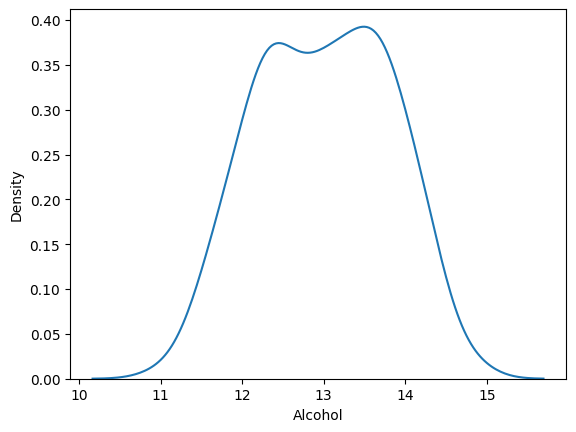

In [17]:
sns.kdeplot(df['Alcohol'] )

In [12]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 178 entries, 1 to 178
Data columns (total 3 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   Class Label  178 non-null    object
 1   Alcohol      178 non-null    object
 2   Malic acid   178 non-null    object
dtypes: object(3)
memory usage: 4.3+ KB


In [19]:
df['Malic acid'] = pd.to_numeric(df['Malic acid'], errors='coerce')

C:\Users\rohansha\AppData\Local\Temp\ipykernel_43192\1662070944.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['Malic acid'] = pd.to_numeric(df['Malic acid'], errors='coerce')


<Axes: xlabel='Malic acid', ylabel='Density'>

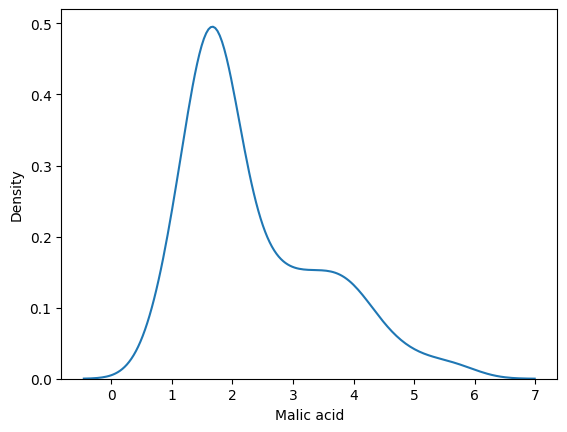

In [20]:
sns.kdeplot(df['Malic acid'] )

In [26]:
df['Class Label'] = pd.to_numeric(df['Class Label'], errors='coerce')

C:\Users\rohansha\AppData\Local\Temp\ipykernel_43192\172475987.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['Class Label'] = pd.to_numeric(df['Class Label'], errors='coerce')


<Axes: xlabel='Alcohol', ylabel='Malic acid'>

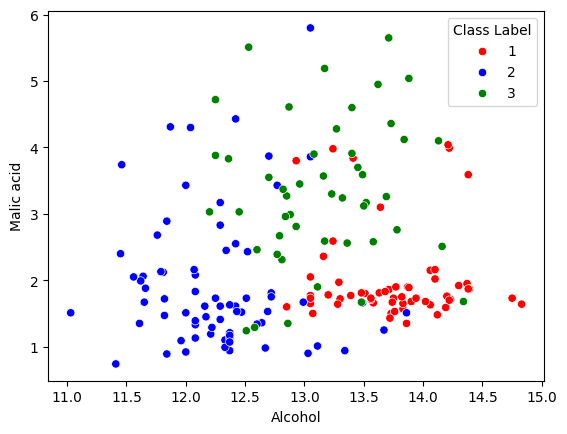

In [27]:
color = { 1:'Red',2:'Blue', 3: 'Green'}

sns.scatterplot(
    data=df, 
    x='Alcohol', 
    y='Malic acid', 
    hue='Class Label', 
    palette=color
)

In [24]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 178 entries, 1 to 178
Data columns (total 3 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Class Label  178 non-null    object 
 1   Alcohol      178 non-null    float64
 2   Malic acid   178 non-null    float64
dtypes: float64(2), object(1)
memory usage: 4.3+ KB


In [28]:
from sklearn.model_selection import train_test_split

In [29]:
X_train, X_test, y_train, y_test = train_test_split(df.drop('Class Label', axis = 1), df['Class Label'], test_size =0.3 , random_state =0)

In [30]:
X_train.shape, X_test.shape

((124, 2), (54, 2))

In [31]:
from sklearn.preprocessing import MinMaxScaler

In [32]:
scaler = MinMaxScaler()

In [33]:
scaler.fit(X_train)

,"feature_range feature_range: tuple (min, max), default=(0, 1)Desired range of transformed data.","(0, ...)"
,"copy copy: bool, default=TrueSet to False to perform inplace row normalization and avoid acopy (if the input is already a numpy array).",True
,"clip clip: bool, default=FalseSet to True to clip transformed values of held-out data toprovided `feature_range`.Since this parameter will clip values, `inverse_transform` may notbe able to restore the original data... note:: Setting `clip=True` does not prevent feature drift (a distribution shift between training and test data). The transformed values are clipped to the `feature_range`, which helps avoid unintended behavior in models sensitive to out-of-range inputs (e.g. linear models). Use with care, as clipping can distort the distribution of test data... versionadded:: 0.24",False


In [34]:
X_train_scaled = scaler.transform(X_train)

In [35]:
X_test_scaled = scaler.transform(X_test)

In [37]:
X_test_scaled = pd.DataFrame(X_test_scaled, columns = X_train.columns)
X_train_scaled = pd.DataFrame(X_train_scaled, columns = X_train.columns)

In [38]:
X_train_scaled

,Alcohol,Malic acid
0,0.720430,0.203782
1,0.319892,0.084034
2,0.602151,0.712185
3,0.572581,0.563025
4,0.760753,0.130252
...,...,...
119,0.212366,0.174370
120,0.360215,0.058824
121,0.373656,0.151261
122,0.771505,0.165966


In [39]:
np.round(X_train.describe(), 1)

,Alcohol,Malic acid
count,124.0,124.0
mean,13.0,2.4
std,0.8,1.1
min,11.0,0.9
25%,12.4,1.6
50%,13.0,1.9
75%,13.6,3.2
max,14.8,5.6


In [40]:
np.round(X_train_scaled.describe(), 1)

,Alcohol,Malic acid
count,124.0,124.0
mean,0.5,0.3
std,0.2,0.2
min,0.0,0.0
25%,0.4,0.2
50%,0.5,0.2
75%,0.7,0.5
max,1.0,1.0


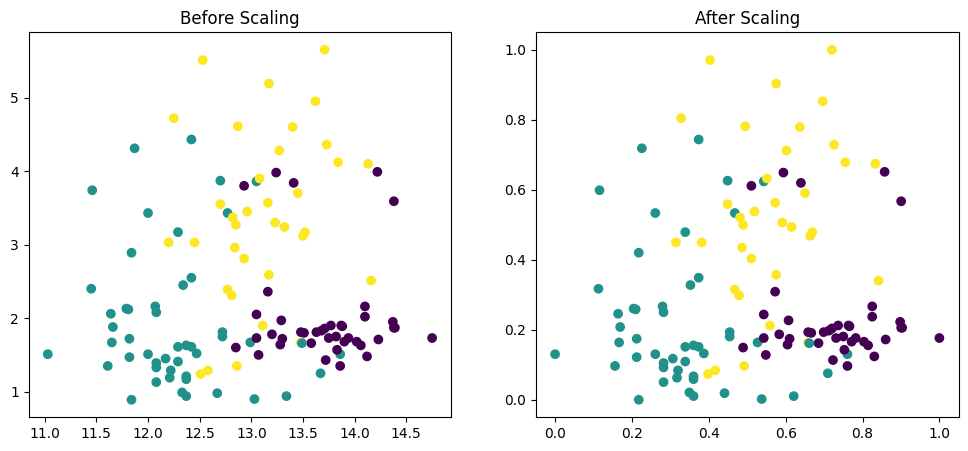

In [41]:
fig , (ax1, ax2) = plt.subplots(ncols =2, figsize= (12,5))

ax1.scatter(X_train['Alcohol'],X_train['Malic acid'] , c =y_train)
ax1.set_title("Before Scaling")
ax2.scatter(X_train_scaled['Alcohol'], X_train_scaled['Malic acid'],c = y_train)
ax2.set_title("After Scaling")
plt.show()

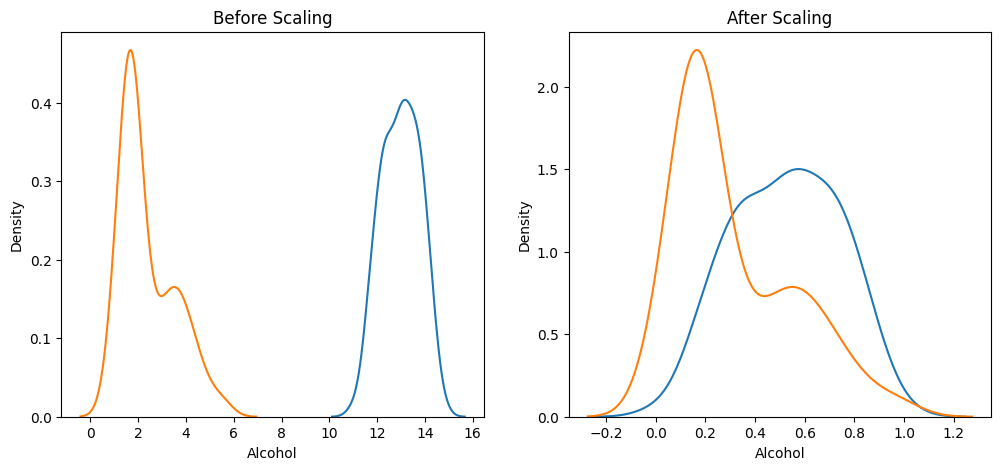

In [42]:
fig, (ax1, ax2) = plt.subplots(ncols = 2, figsize = (12,5))

# before scaling
ax1.set_title('Before Scaling')
sns.kdeplot(X_train['Alcohol'], ax = ax1)
sns.kdeplot(X_train['Malic acid'], ax = ax1)

# after scaling 

ax2.set_title('After Scaling')
sns.kdeplot(X_train_scaled['Alcohol'], ax = ax2)
sns.kdeplot(X_train_scaled['Malic acid'], ax = ax2)
plt.show()